In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3

from datetime import date

In [2]:
today = date.today()
date = today.strftime("%d_%m_%Y")

In [3]:
nucleus_studies = ['Duong_lungMAP_unpubl', 'Eils_2020', 'Sun_2020']
nucleus_datasets = ['Duong_lungMAP_unpubl', 'Eils_2020', 'Sun_2020_batch1', 'Sun_2020_batch2', 'Sun_2020_batch3', 'Sun_2020_batch4']

In [4]:
# Import datasets with Milos differential abundance values for k = 50 
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_denovo_recalc_milo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_denovo_ref_milo.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_scarches_unlabeled_milo.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_scarches_labeled_milo.h5ad")

In [5]:
# Import milo logFC values calculated with k=150
denovo_recalc_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_denovo_recalc_logFC.h5ad")
denovo_ref_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_denovo_ref_logFC.h5ad")
scarches_unlabeled_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_scarches_unlabeled_logFC.h5ad")
scarches_labeled_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_scarches_labeled_logFC.h5ad")

In [6]:
# Update milo logFC values with new ones calculated with k=150
denovo_recalc.obs.logFC_avg = denovo_recalc_logFC_avg
denovo_ref.obs.logFC_avg = denovo_ref_logFC_avg
scarches_unlabeled.obs.logFC_avg = scarches_unlabeled_logFC_avg
scarches_labeled.obs.logFC_avg = scarches_labeled_logFC_avg

In [7]:
# Show how many cells,datasets,studies are included in reference and query
ncells = denovo_recalc.obs.groupby("origin").size()
ndata = denovo_recalc.obs.groupby("origin").dataset.nunique()
nstudy = denovo_recalc.obs.groupby("origin").study.nunique()

names = ["cells", "datasets", "studies"]
counts_nucleus = pd.concat([ncells,ndata,nstudy],axis=1)
counts_nucleus = counts_nucleus.rename({0:"cells"},axis=1)
counts_nucleus

,cells,dataset,study
origin,,,
query,140182,6,3
reference,584884,14,11


In [8]:
denovo_ref.obs.loc[:,["dataset","study","origin"]].drop_duplicates()

,dataset,study,origin
GCGACCATCCCTAACC_SC22-0,Misharin_Budinger_2018,Misharin_Budinger_2018,reference
P2_1_GCGCAACCAGTTAACC-0,Krasnow_2020,Krasnow_2020,reference
CTTGATTGTCAGTTTG_T164-0,Seibold_2020_10Xv3,Seibold_2020,reference
GTCACGGAGACGCAAC_F02617-0,Banovich_Kropski_2020,Banovich_Kropski_2020,reference
CAGCCACAGTCACTA_GRO-03_biopsy-0,Nawijn_2021,Nawijn_2021,reference
TCATGAGGTCGCAGTC_SC142-0,Misharin_2021,Misharin_2021,reference
TAAGTGCCACTGTTAG_T121-0,Seibold_2020_10Xv2,Seibold_2020,reference
D363_Brus_Dis1_ATAAGAGAGCACCGTC-1-26-0,Barbry_Leroy_2020,Barbry_Leroy_2020,reference
7185212_CTGGTCTCACTGTTAG-0,Teichmann_Meyer_2019,Teichmann_Meyer_2019,reference
ACCCACTGAACTGC-SC14-0,Lafyatis_Rojas_2019_10Xv1,Lafyatis_Rojas_2019,reference


In [9]:
#Import color palette to get consistent colors across figures
import pickle  
with open('/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/colordict.pkl', 'rb') as f:
        colordict = pickle.load(f)

In [10]:
# get original scanvi_labels for scarches_unlabeld back
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("string")
scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label_original"] = scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label"].astype(str)
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("category")

In [11]:
scarches_unlabeled.obs["diff_denovo_recalc"] = abs(scarches_unlabeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
scarches_unlabeled.obs["diff_denovo_ref"] = abs(scarches_unlabeled.obs.logFC_avg - denovo_ref.obs.logFC_avg)
scarches_unlabeled.obs["diff_scArches_labeled"] = abs(scarches_unlabeled.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
scarches_labeled.obs["diff_denovo_recalc"] = abs(scarches_labeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
scarches_labeled.obs["diff_denovo_ref"] = abs(scarches_labeled.obs.logFC_avg - denovo_ref.obs.logFC_avg)
scarches_labeled.obs["diff_scArches_unlabeled"] = abs(scarches_labeled.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_ref.obs["diff_denovo_recalc"] = abs(denovo_ref.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
denovo_ref.obs["diff_scArches_labeled"] = abs(denovo_ref.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
denovo_ref.obs["diff_scArches_unlabeled"] = abs(denovo_ref.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_recalc.obs["diff_scArches_unlabeled"] = abs(denovo_recalc.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_recalc.obs["diff_scArches_labeled"] = abs(denovo_recalc.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
denovo_recalc.obs["diff_denovo_ref"] = abs(denovo_recalc.obs.logFC_avg - denovo_ref.obs.logFC_avg)

In [12]:
del scarches_unlabeled.uns['scanvi_label_colors']
del scarches_labeled.uns['scanvi_label_colors']
del denovo_recalc.uns['scanvi_label_colors']
del denovo_ref.uns['scanvi_label_colors']

In [13]:
scarches_unlabeled_plot = sc.pp.subsample(scarches_unlabeled, fraction=1., copy=True)
scarches_labeled_plot = sc.pp.subsample(scarches_labeled, fraction=1., copy=True)
denovo_ref_plot = sc.pp.subsample(denovo_ref, fraction=1., copy=True)
denovo_recalc_plot = sc.pp.subsample(denovo_recalc, fraction=1., copy=True)

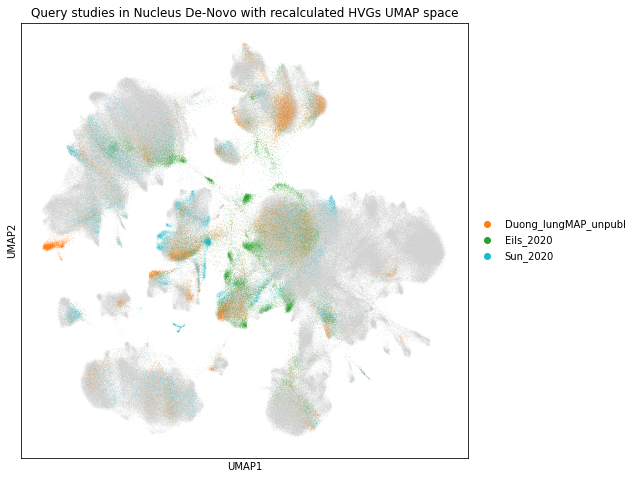

In [14]:
sc.pl.umap(denovo_recalc_plot, color="study",  size = 0.5, sort_order = False, groups = nucleus_studies, palette ="tab10",
          title = "Query studies in Nucleus De-Novo with recalculated HVGs UMAP space", na_in_legend=False
          #save = f"_nucleus_denovo_recalc_origin_{date}.png"
          )

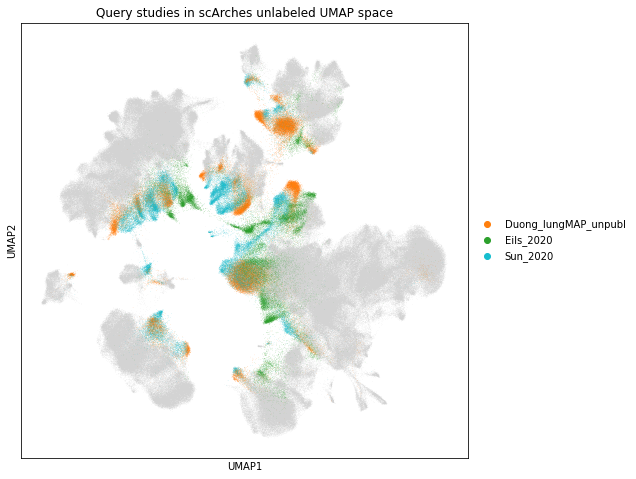

In [15]:
sc.pl.umap(scarches_unlabeled_plot, color="study",  size = 0.5, sort_order = False, groups = nucleus_studies, palette = "tab10",
          title = "Query studies in scArches unlabeled UMAP space", na_in_legend=False
          #save = f"_nucleus_denovo_recalc_origin_{date}.png"
          )

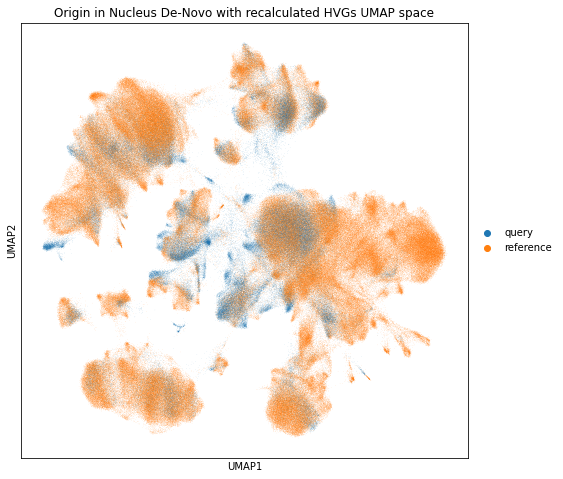

In [16]:
sc.pl.umap(denovo_recalc_plot, color="origin", palette = colordict, size = 0.3, sort_order = False,
          title = "Origin in Nucleus De-Novo with recalculated HVGs UMAP space",
          save = f"_nucleus_denovo_recalc_origin_{date}.png")


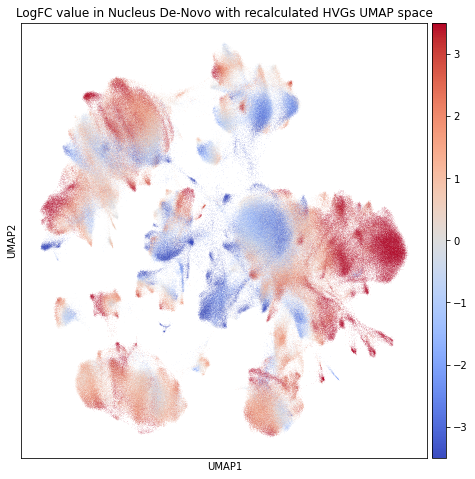

In [17]:
sc.pl.umap(denovo_recalc_plot, color="logFC_avg",color_map="coolwarm",vmin=-3.5,vmax=3.5, size = 0.3, sort_order = False,
          title = "LogFC value in Nucleus De-Novo with recalculated HVGs UMAP space",
          save = f"_nucleus_denovo_recalc_logFC_{date}.png")

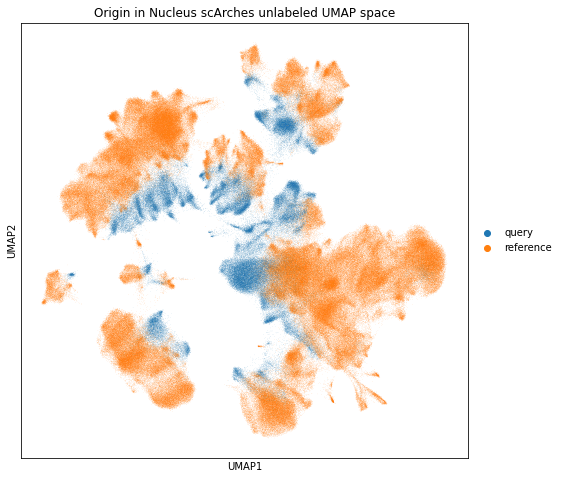

In [18]:
sc.pl.umap(scarches_unlabeled_plot, color="origin", palette = colordict, size = 0.3, sort_order = False,
          title = "Origin in Nucleus scArches unlabeled UMAP space", 
          save = f"_nucleus_scarches_unlabeled_origin_{date}.png")

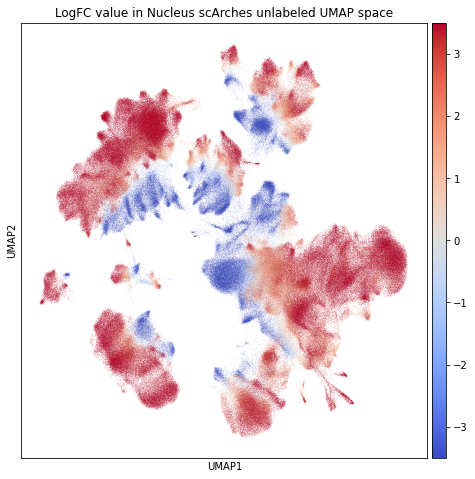

In [19]:
sc.pl.umap(scarches_unlabeled_plot, color="logFC_avg", color_map = "coolwarm", vmin = -3.5, vmax = 3.5, size = 0.3, sort_order = False,
          title = "LogFC value in Nucleus scArches unlabeled UMAP space",
          save = f"_nucleus_scarches_unlabeled_logFC_{date}.png")

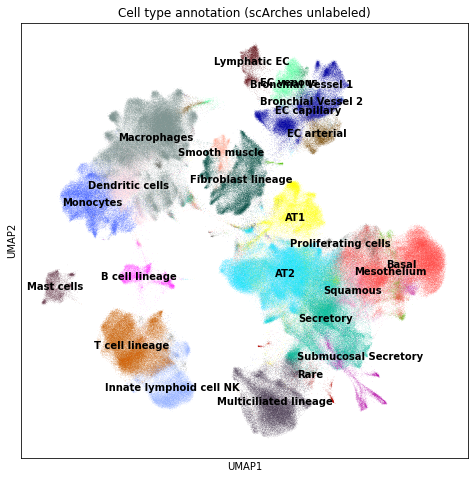

In [20]:
sc.pl.umap(scarches_unlabeled_plot, color = "C_scArches", palette = colordict, legend_loc = "on data", size = 0.3, sort_order = False,
          title = "Cell type annotation (scArches unlabeled)",
          save = f"_nucleus_scarches_unlabeled_annotation_{date}.png")

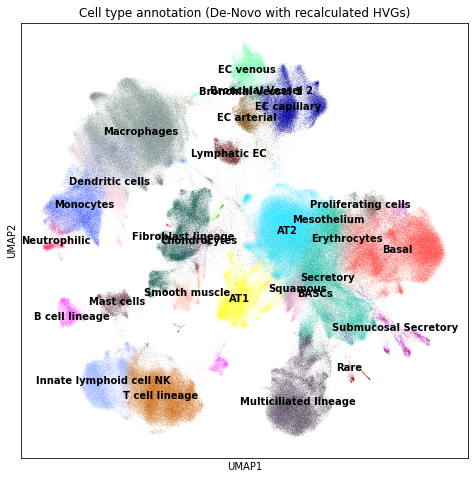

In [21]:
sc.pl.umap(denovo_recalc_plot, color = "C_scANVI", palette = colordict, legend_loc = "on data", size = 0.3, sort_order = False,
          title = "Cell type annotation (De-Novo with recalculated HVGs)",
          save = f"_nucleus_denovo_recalc_annotation_{date}.png")

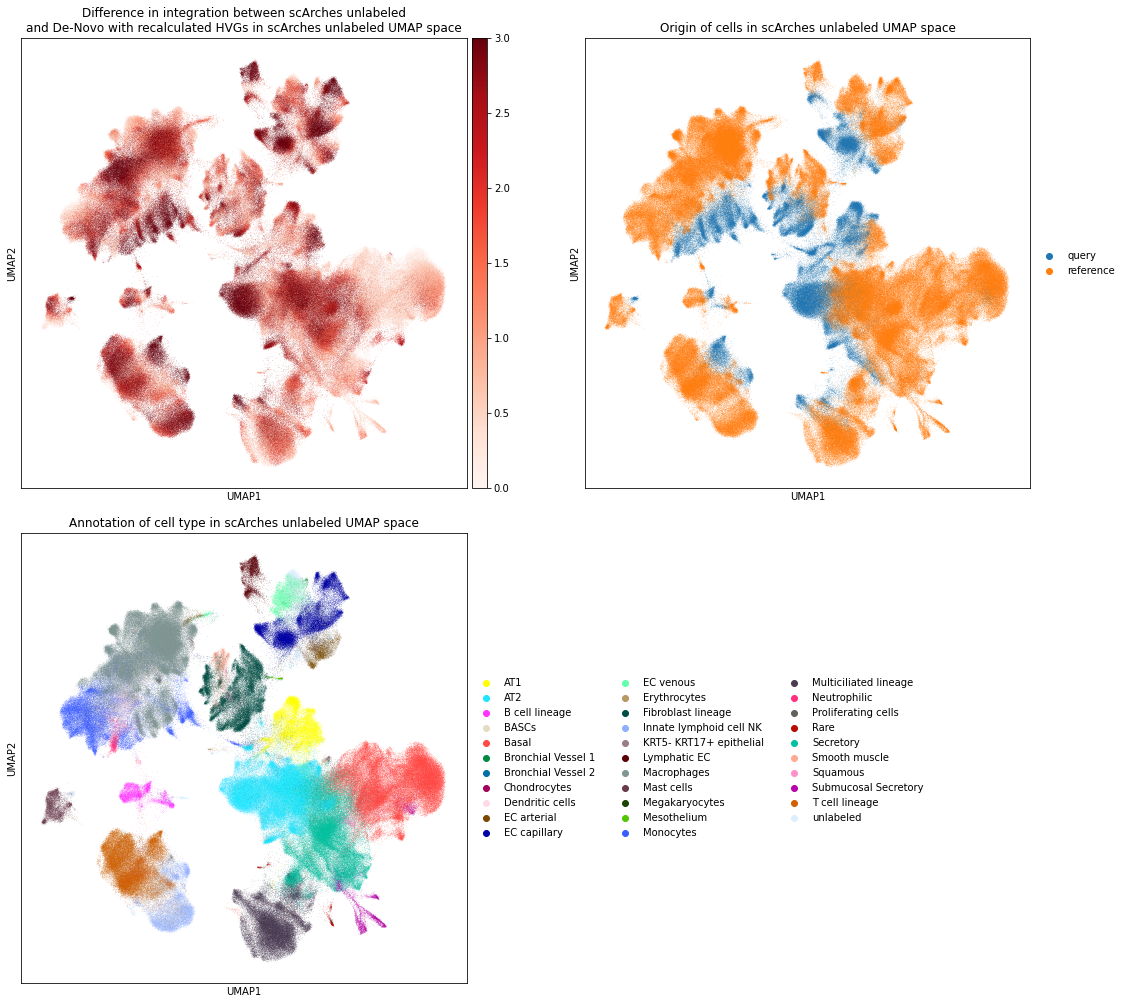

In [22]:
sc.pl.umap(scarches_unlabeled_plot, color = ["diff_denovo_recalc", "origin", "scanvi_label_original"], 
          vmin = 0, vmax = 3, cmap = "Reds", palette = colordict, size = 0.5, sort_order = False, wspace=0.15, hspace = 0.1, ncols = 2,
          save = f"_nucleus_scarches_unlabeled_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in scArches unlabeled UMAP space",
                  "Origin of cells in scArches unlabeled UMAP space",
                  "Annotation of cell type in scArches unlabeled UMAP space"])

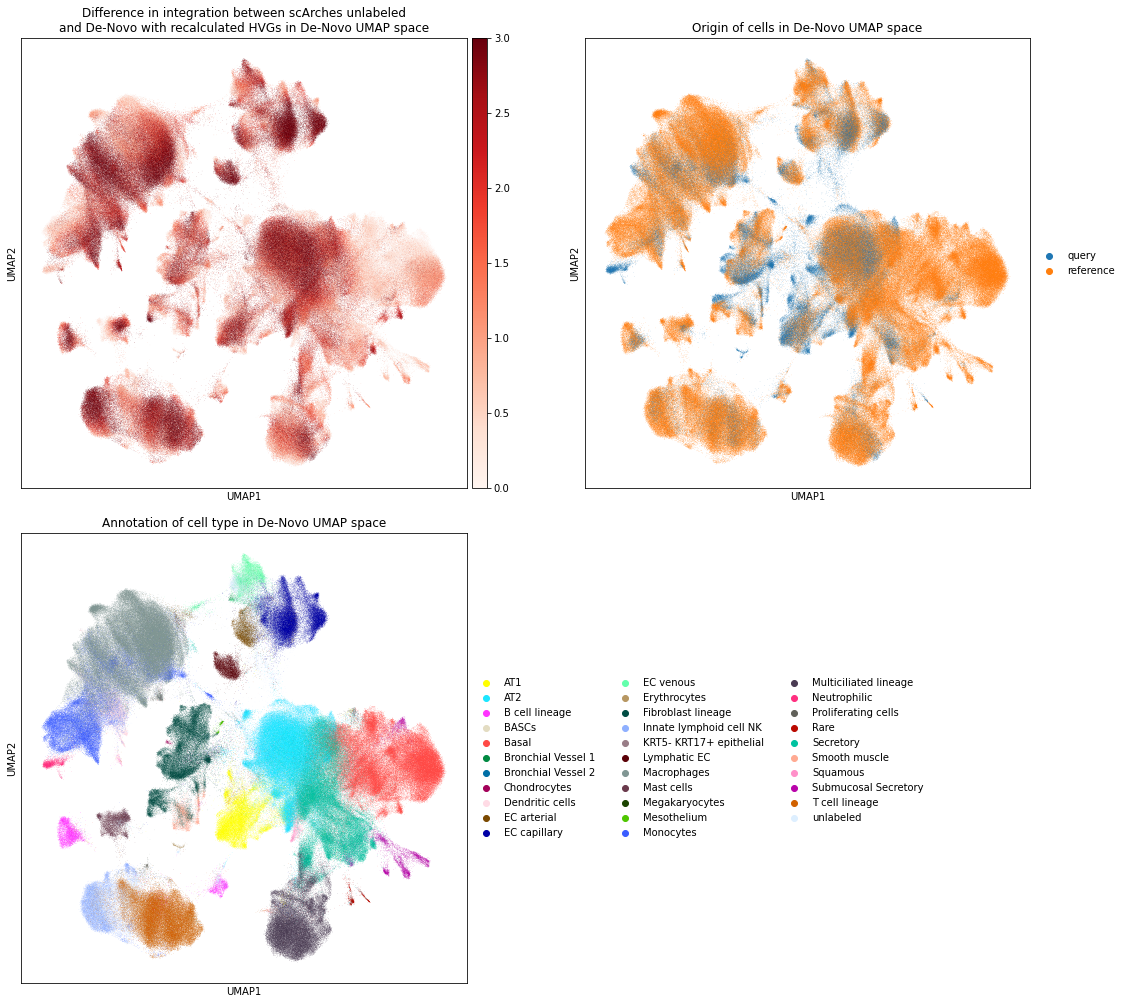

In [23]:
sc.pl.umap(denovo_recalc_plot, color = ["diff_scArches_unlabeled", "origin", "scanvi_label"], 
          vmin = 0, vmax = 3, cmap = "Reds", palette = colordict, size = 0.5, sort_order = False, wspace=0.15, hspace = 0.1, ncols = 2,
          save= f"_nucleus_denovo_recalc_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in De-Novo UMAP space",
                  "Origin of cells in De-Novo UMAP space",
                  "Annotation of cell type in De-Novo UMAP space"])

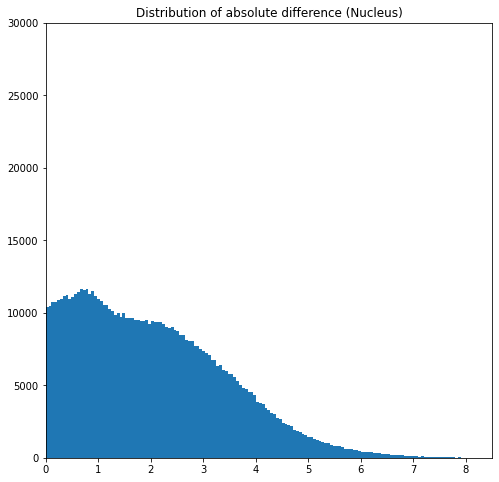

In [32]:
plt.hist(scarches_unlabeled.obs.diff_denovo_recalc, bins=200)
plt.ylim(0,30000)
plt.xlim(0,8.5)
plt.title("Distribution of absolute difference (Nucleus)")
plt.savefig(f"figures/nucleus_distr_abs_diff_{date}.png")

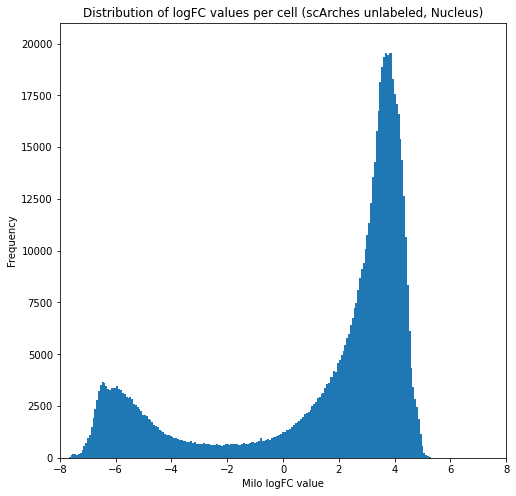

In [33]:
plt.hist(scarches_unlabeled.obs.logFC_avg, bins=200)
plt.ylim(0,21000)
plt.xlim(-8,8)
plt.title("Distribution of logFC values per cell (scArches unlabeled, Nucleus)")
plt.xlabel("Milo logFC value")
plt.ylabel("Frequency")
plt.savefig(f"figures/nucleus_scarches_unlabeled_distr_logFC_{date}.png")

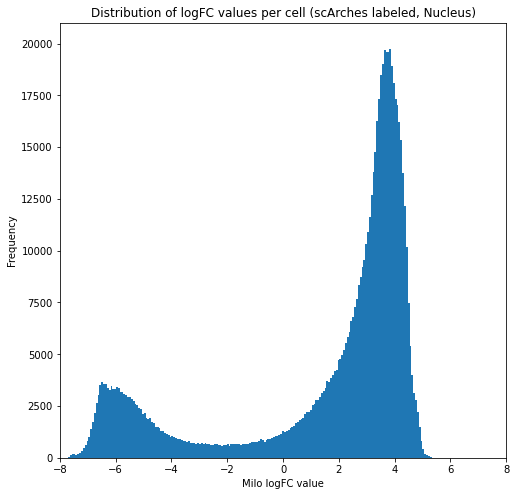

In [34]:
plt.hist(scarches_labeled.obs.logFC_avg, bins=200)
plt.ylim(0,21000)
plt.xlim(-8,8)
plt.title("Distribution of logFC values per cell (scArches labeled, Nucleus)")
plt.xlabel("Milo logFC value")
plt.ylabel("Frequency")
plt.savefig(f"figures/nucleus_scarches_labeled_distr_logFC_{date}.png")

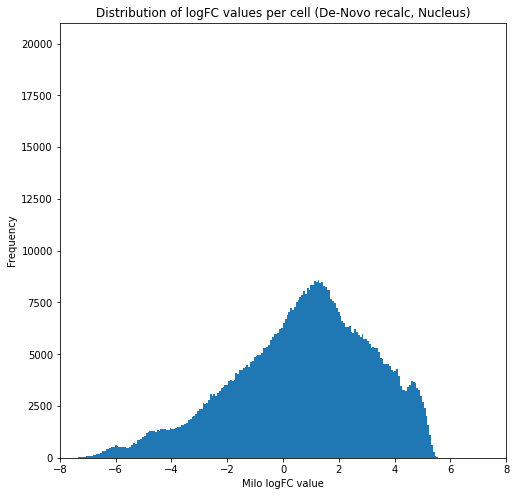

In [35]:
plt.hist(denovo_recalc.obs.logFC_avg, bins=200)
plt.ylim(0,21000)
plt.xlim(-8,8)
plt.title("Distribution of logFC values per cell (De-Novo recalc, Nucleus)")
plt.xlabel("Milo logFC value")
plt.ylabel("Frequency")
plt.savefig(f"figures/nucleus_denovo_recalc_distr_logFC_{date}.png")

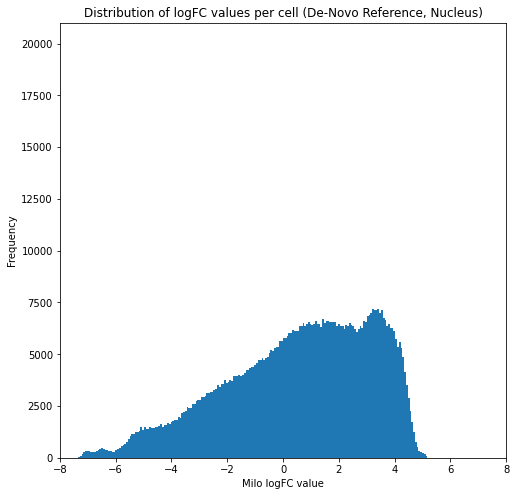

In [36]:
plt.hist(denovo_ref.obs.logFC_avg, bins=200)
plt.ylim(0,21000)
plt.xlim(-8,8)
plt.title("Distribution of logFC values per cell (De-Novo Reference, Nucleus)")
plt.xlabel("Milo logFC value")
plt.ylabel("Frequency")
plt.savefig(f"figures/nucleus_denovo_ref_distr_logFC_{date}.png")

# Violin Plots 

I got no cell type to investigate for Nucleus data.

In [30]:
# Sort labels by median of difference of logFC value
labels_sorted = list(scarches_unlabeled.obs.groupby("scanvi_label_original")["diff_denovo_recalc"].median().sort_values().index)

In [31]:
sort_by = [labels_sorted.index(x) for x in sorted(labels_sorted)]

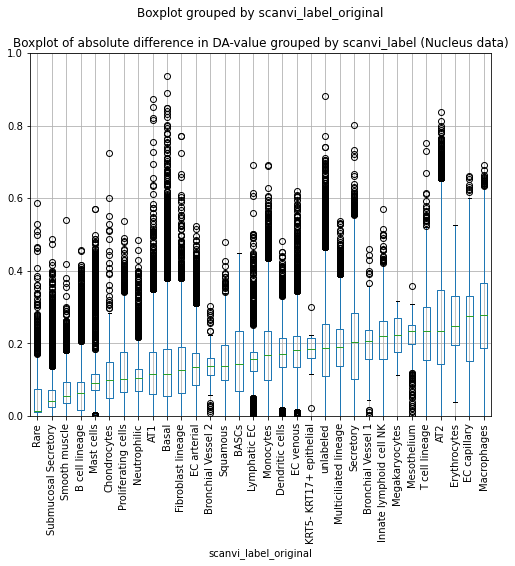

In [32]:
scarches_unlabeled.obs.boxplot(column='diff_denovo_recalc',by='scanvi_label_original', positions=sort_by )
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by scanvi_label (Nucleus data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/nucleus_boxplot_scanvi_label_{date}.jpg")

In [33]:
cell_labels_lvl3 = ["Erythroblast", "KRT5- KRT17+ epithelial"]
cell_labels_lvl4 = ["Fibroblasts PLIN2+", "Ionocyte", "Neuroendocrine", "Langerin+ DC", "Regulatory T cells", "T cells proliferating"]

cells_lvl3 = denovo_recalc[denovo_recalc.obs["ann_level_3"].isin(cell_labels_lvl3)]
cells_lvl4 = denovo_recalc[denovo_recalc.obs["ann_level_4"].isin(cell_labels_lvl4)]

In [34]:
labels_sorted_lvl3 = list(cells_lvl3.obs.groupby("ann_level_3")["diff_scArches_unlabeled"].median().sort_values().index)
labels_sorted_lvl4 = list(cells_lvl4.obs.groupby("ann_level_4")["diff_scArches_unlabeled"].median().sort_values().index)

In [35]:
sort_by_lvl3 = [labels_sorted_lvl3.index(x) for x in sorted(labels_sorted_lvl3)]
sort_by_lvl4 = [labels_sorted_lvl4.index(x) for x in sorted(labels_sorted_lvl4)]

In [37]:
cell_labels_lvl3

['Erythroblast', 'KRT5- KRT17+ epithelial']

ValueError: not enough values to unpack (expected 2, got 0)

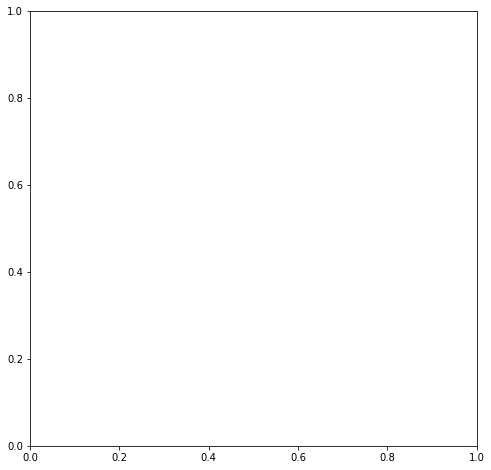

In [44]:
cells_lvl3.obs.boxplot(column='diff_scArches_unlabeled',by='ann_level_3', positions=sort_by_lvl3)
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by cell types lvl3 (Nucleus data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/nucleus_boxplot_new_lvl3_{date}.jpg")

In [ ]:
cells_lvl4.obs.boxplot(column='diff_denovo_recalc',by='ann_level_4', positions=sort_by_lvl4)
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-values for cell type lvl4 (Nucleus data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/nucleus_boxplot_lvl4_{date}.jpg")

# Clustering analysis

In [47]:
sc.tl.leiden(denovo_recalc, resolution= 0.1)

running Leiden clustering
    finished: found 12 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:17:09)


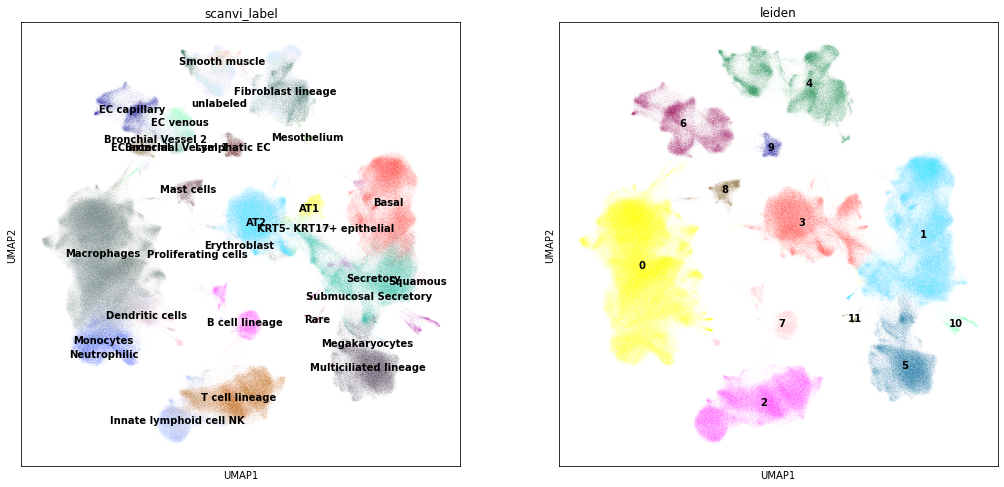

In [48]:
sc.pl.umap(denovo_recalc, color=["scanvi_label","leiden"], legend_loc="on data")

In [49]:
subset_immune = denovo_recalc[(denovo_recalc.obs.leiden == "0") | (denovo_recalc.obs.leiden == "2")].copy()

/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)


In [50]:
sc.pp.neighbors(subset_immune, n_neighbors=50, n_pcs=30, use_rep="X_scANVI")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:07:39)


In [51]:
sc.tl.umap(subset_immune)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:14:54)


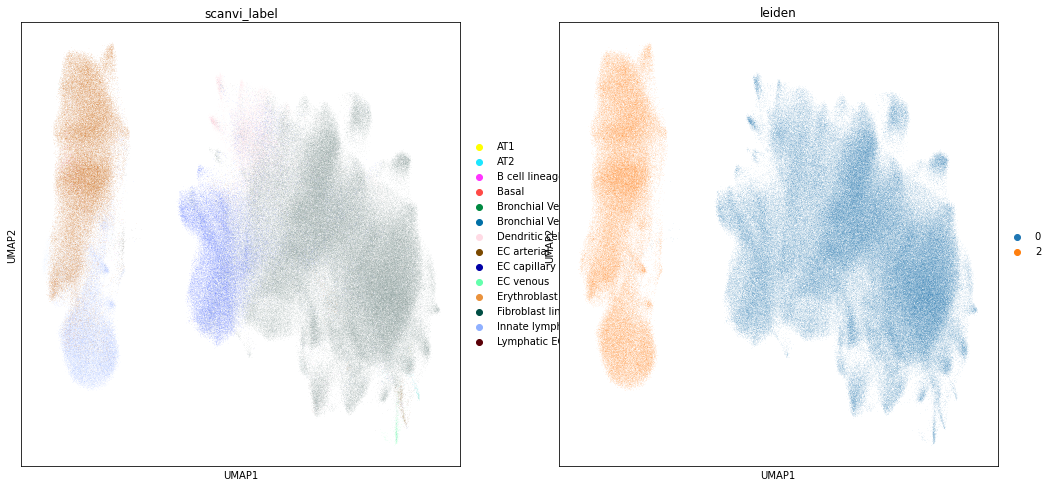

In [52]:
sc.pl.umap(subset_immune, color=["scanvi_label","leiden"])

In [53]:
sc.tl.leiden(subset_immune, resolution= 0.5,key_added = "leiden_sub")

running Leiden clustering
    finished: found 14 clusters and added
    'leiden_sub', the cluster labels (adata.obs, categorical) (0:16:03)


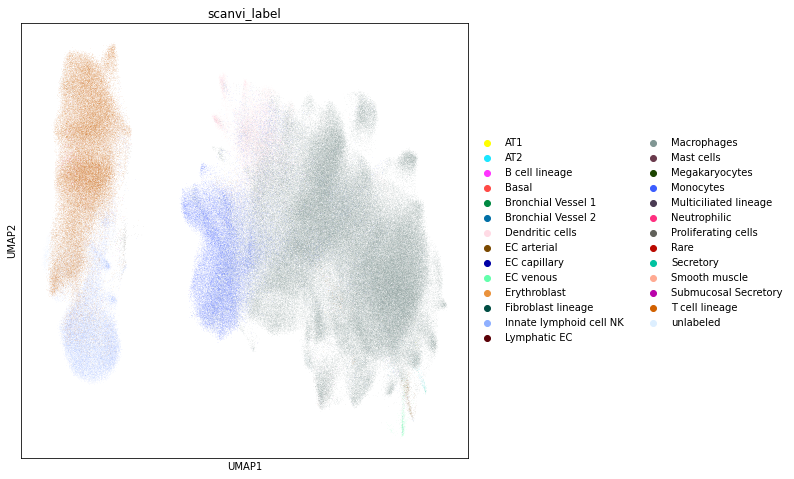

In [54]:
sc.pl.umap(subset_immune, color=["scanvi_label"])

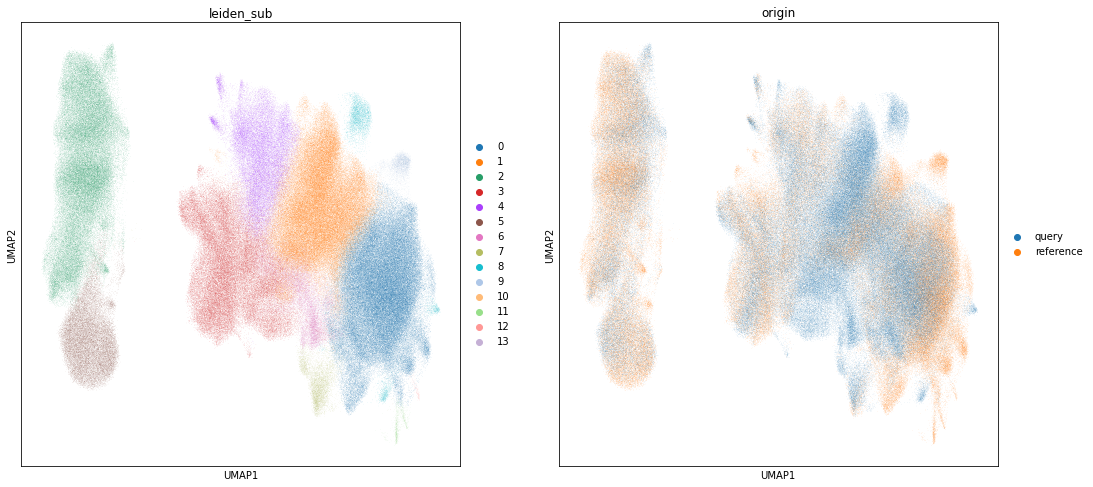

In [55]:
sc.pl.umap(subset_immune, color=["leiden_sub", "origin"])

In [124]:
subset_immune.raw.var.index = subset_immune.raw.var["gene_symbols-0"]

In [125]:
subset_immune.raw.var_names

CategoricalIndex(['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112', 'FGR', 'CFH',
                  'FUCA2', 'GCLC', 'NFYA',
                  ...
                  nan, nan, nan, nan, nan, nan, nan, nan, nan, nan],
                 categories=['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1', 'A2ML1', 'A2ML1-AS1', 'A2ML1-AS2', ...], ordered=False, name='gene_symbols-0', dtype='category', length=48717)

In [126]:
subset_immune.raw.var.index

CategoricalIndex(['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112', 'FGR', 'CFH',
                  'FUCA2', 'GCLC', 'NFYA',
                  ...
                  nan, nan, nan, nan, nan, nan, nan, nan, nan, nan],
                 categories=['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1', 'A2ML1', 'A2ML1-AS1', 'A2ML1-AS2', ...], ordered=False, name='gene_symbols-0', dtype='category', length=48717)

ranking genes
    finished: added to `.uns['t-test']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:01:38)


IndexError: index 25 is out of bounds for axis 0 with size 25

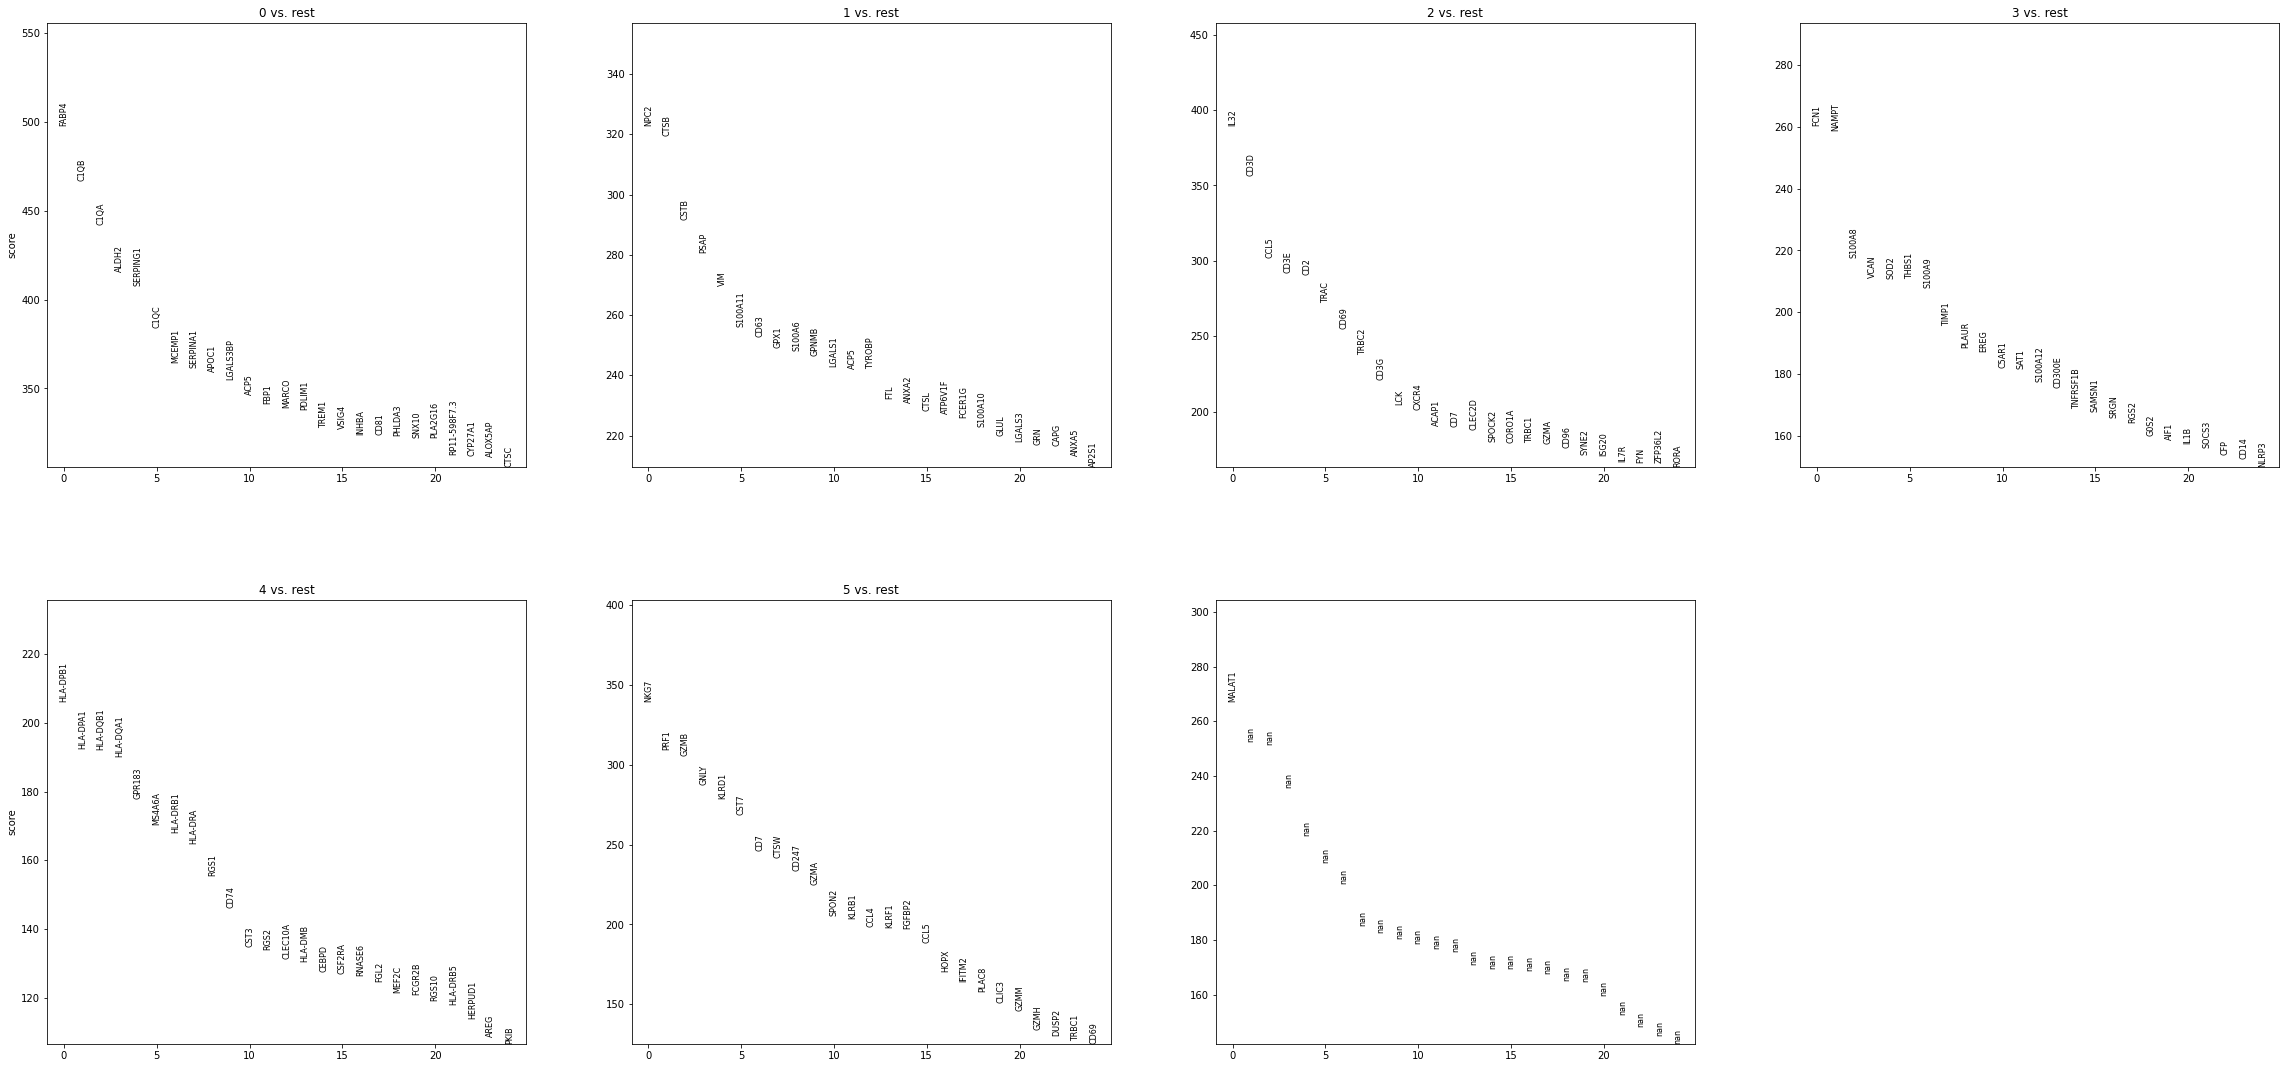

In [127]:
sc.tl.rank_genes_groups(subset_immune, 'leiden_sub', method='t-test', key_added = "t-test", use_raw=True)
sc.pl.rank_genes_groups(subset_immune, n_genes=25, sharey=False, key = "t-test", gene_symbols = "gene_symbols-0")

In [1]:
subset_immune

NameError: name 'subset_immune' is not defined

In [ ]:
sc.tl.filter_rank_genes_groups(subset_immune, min_fold_change=3, key="t-test", use_raw=True)

Filtering genes using: min_in_group_fraction: 0.25 min_fold_change: 3, max_out_group_fraction: 0.5


In [ ]:
subset_immune.uns["rank_genes_groups_filtered"]

In [ ]:
# visualize results
sc.pl.rank_genes_groups(subset_immune, key='rank_genes_groups_filtered')

In [ ]:
sc.get.rank_genes_groups_df(subset_immune, key='rank_genes_groups_filtered')

In [ ]:
# visualize results using dotplot
sc.pl.rank_genes_groups_dotplot(subset_immune, n_genes=5, key='rank_genes_groups_filtered',  gene_symbols = "gene_symbols-0")

In [59]:
sc.logging.print_versions()


-----
anndata     0.7.5
scanpy      1.8.2
sinfo       0.3.1
-----
PIL                 8.1.0
anndata             0.7.5
anyio               NA
attr                20.3.0
babel               2.9.0
backcall            0.2.0
brotli              1.0.9
certifi             2020.12.05
cffi                1.14.4
chardet             4.0.0
cloudpickle         1.6.0
constants           NA
cycler              0.10.0
cython_runtime      NA
dask                2020.12.0
dateutil            2.8.1
decorator           4.4.2
future_fstrings     NA
google              NA
h5py                2.10.0
highs_wrapper       NA
idna                2.10
igraph              0.8.3
ipykernel           5.4.3
ipython_genutils    0.2.0
ipywidgets          7.6.3
jedi                0.18.0
jinja2              2.11.2
joblib              1.0.0
json5               NA
jsonschema          3.2.0
jupyter_server      1.2.1
jupyterlab_server   2.1.2
kiwisolver          1.3.1
leidenalg           0.8.3
llvmlite            0.35.0
louv